In [6]:
import pandas as pd
import numpy as np

In [7]:
df = pd.read_csv('synthetic_mof_synthesis.csv')
df.head(2)

,sample_id,mof_family,metal_salt,linker,solvent,modulator,modulator_equiv,metal_linker_ratio,concentration_M,temperature_C,time_h,batch,relative_crystallinity,phase_outcome,yield_pct,BET_m2_g
0,M0000,MIL-53(Al),Al(NO3)3,terephthalic acid,H2O,none,0,0.84,0.104,210.7,35.30,6,0.673,phase-pure MOF,80.0,609.0
1,M0001,UiO-66,ZrCl4,terephthalic acid,DMF,none,0,0.92,0.091,108.1,8.49,8,0.751,phase-pure MOF,68.2,818.0


In [8]:
df['phase_outcome'].value_counts()

phase_outcome
phase-pure MOF     357
mixed phase        233
amorphous/other     70
Name: count, dtype: int64

In [9]:
mapping = {'phase-pure MOF': 0, 'mixed phase':1, 'amorphous/other':2}

df['phase_outcome'] = df['phase_outcome'].map(mapping)
df['phase_outcome'].value_counts()


phase_outcome
0    357
1    233
2     70
Name: count, dtype: int64

In [10]:
df2 = df.drop(columns=['sample_id',	'mof_family',	'temperature_C', 'batch', 'metal_salt',	'linker',	'solvent',	'modulator', 'time_h', 'BET_m2_g', 'yield_pct', 'modulator_equiv'])
df2.head(2)

,metal_linker_ratio,concentration_M,relative_crystallinity,phase_outcome
0,0.84,0.104,0.673,0
1,0.92,0.091,0.751,0


In [11]:
df2 = df2.rename(columns = {'metal_linker_ratio': 'feature1',
                           'concentration_M': 'feature2',
                           'relative_crystallinity': 'feature3',
                           'phase_outcome': 'target'})
df2.head()

,feature1,feature2,feature3,target
0,0.84,0.104,0.673,0
1,0.92,0.091,0.751,0
2,6.90,0.065,0.157,2
3,1.27,0.159,0.701,0
4,1.75,0.063,0.428,1


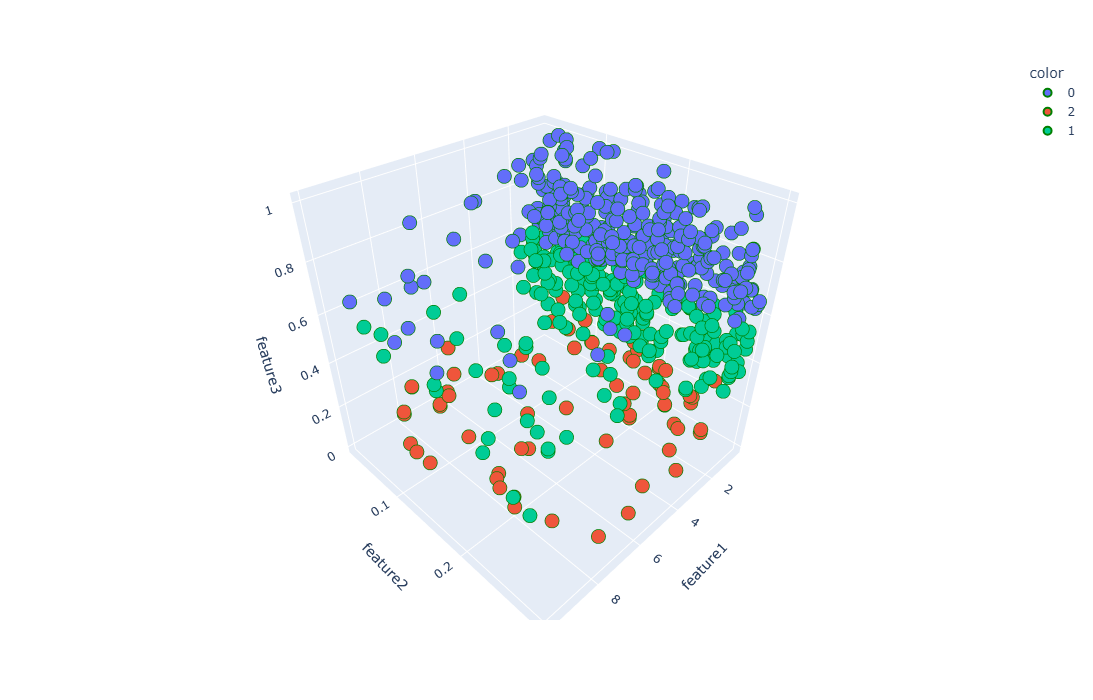

In [12]:
import plotly.express as px



fig = px.scatter_3d(df2, x=df2['feature1'], y=df2['feature2'], 
                   z=df2['feature3'], color = df2['target'].astype('str'), width=900, height=700)

fig.update_traces(marker = dict(size = 8, line = dict(width = 2, color='green')),
                 selector = dict(mode='markers'))

fig.show()

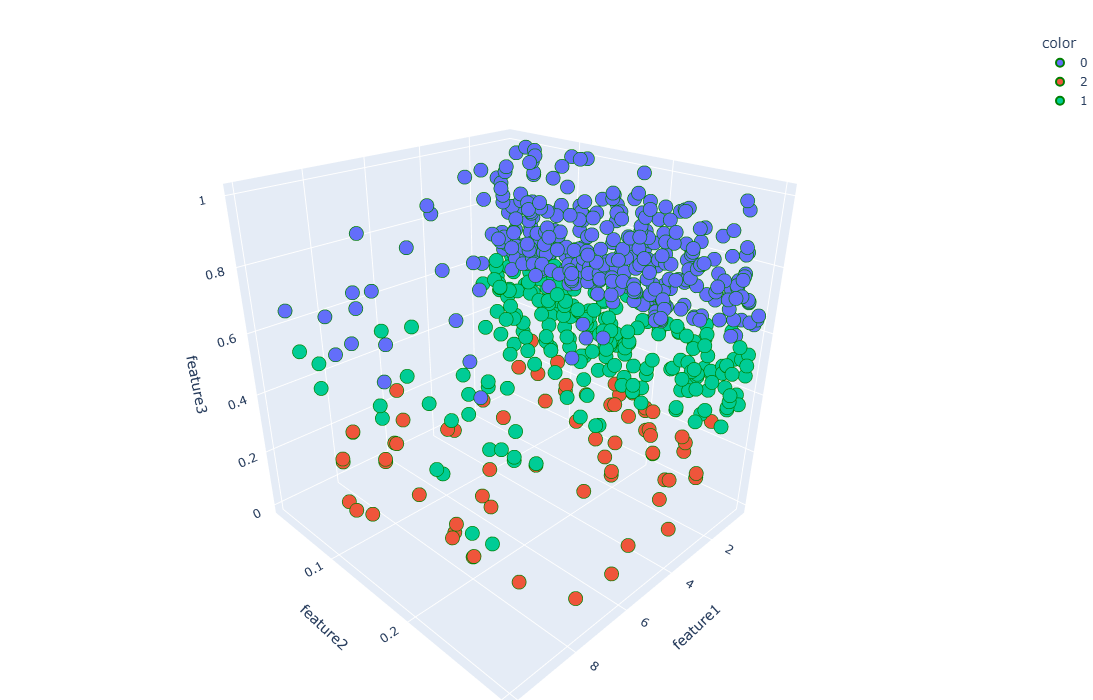

In [13]:

fig = px.scatter_3d(df2, x=df2['feature1'], y=df2['feature2'], 
                   z=df2['feature3'], color = df2['target'].astype('str'), width=900, height=700)

fig.update_traces(marker = dict(size = 8, line = dict(width = 2, color='green')),
                 selector = dict(mode='markers'))

fig.update_layout(margin=dict(l=0, r=0, t=30, b=0),            # removes the white space
                  scene_camera=dict(eye=dict(x=1.4, y=1.4, z=1.0)))   # zooms in a little

fig.show()

## Step 1 - Apply standard scaling -- mean centering

In [14]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

In [15]:
df2.head(2)

,feature1,feature2,feature3,target
0,0.84,0.104,0.673,0
1,0.92,0.091,0.751,0


In [16]:
df2.iloc[:, 0:3] = scaler.fit_transform(df2.iloc[:, 0:3])

## Step 2 - Find Covariance

In [17]:
cov_matrix = np.cov([df2.iloc[:,0], df2.iloc[:,1], df2.iloc[:,2]])
print('cov_matrix:\n', cov_matrix)

cov_matrix:
 [[ 1.00151745 -0.0541496  -0.33156464]
 [-0.0541496   1.00151745 -0.04286454]
 [-0.33156464 -0.04286454  1.00151745]]


## diagonal items are variance of all columns and the others are covariance values

## Step 3 - Find Eigen vector and Eigen value

In [18]:
eigen_values, eigen_vectors = np.linalg.eig(cov_matrix)

eigen_vectors

array([[ 0.6951615 ,  0.70868781,  0.12046608],
       [ 0.1949624 , -0.02457078, -0.9805029 ],
       [ 0.69191051, -0.70509423,  0.15524813]])

In [19]:
eigen_values

array([0.65631681, 1.33327822, 1.01495732])

In [20]:
pc = eigen_vectors[0:2]
pc

array([[ 0.6951615 ,  0.70868781,  0.12046608],
       [ 0.1949624 , -0.02457078, -0.9805029 ]])

In [21]:
transformed_df2 = np.dot(df2.iloc[:, 0:3], pc.T)    ## 650 , 5  - 3,2

new_df2  = pd.DataFrame(transformed_df2, columns=['PC1', 'PC2'])
new_df2['target'] = df2['target'].values

new_df2.head()

,PC1,PC2,target
0,-0.851623,-0.472488,0
1,-0.896044,-0.808485,0
2,0.535223,2.401121,2
3,-0.212899,-0.573855,0
4,-1.042228,0.715719,1


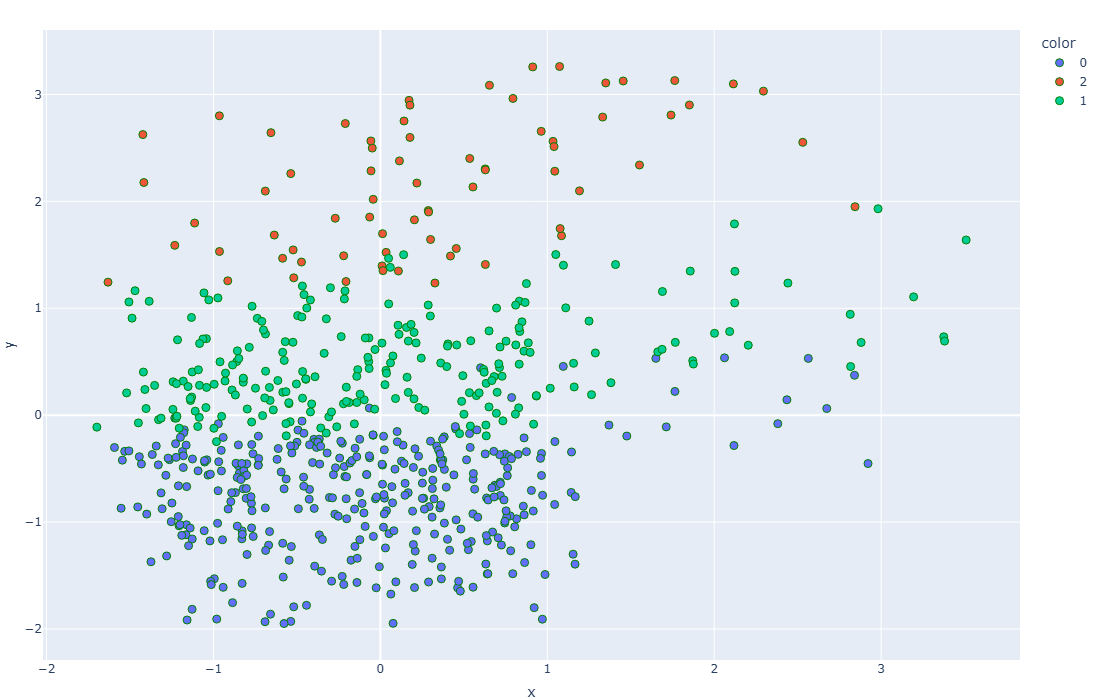

In [22]:
new_df2['target'] = new_df2['target'].astype('str')

fig = px.scatter(x=new_df2['PC1'], y=new_df2['PC2'], 
                   color = new_df2['target'], width=900, height=700)

fig.update_traces(marker = dict(size = 8, line = dict(width = 1, color='green')),
                 selector = dict(mode='markers'))

fig.update_layout(margin=dict(l=0, r=0, t=30, b=0),            # removes the white space
                  scene_camera=dict(eye=dict(x=1.4, y=1.4, z=1.0)))   # zooms in a little

fig.show()

In [1]:
import pandas as pd
import numpy as np
import plotly.express as px

In [3]:
Data_1 = pd.read_csv('synthetic_mof_synthesis.csv')
Data_1.head(2)

,sample_id,mof_family,metal_salt,linker,solvent,modulator,modulator_equiv,metal_linker_ratio,concentration_M,temperature_C,time_h,batch,relative_crystallinity,phase_outcome,yield_pct,BET_m2_g
0,M0000,MIL-53(Al),Al(NO3)3,terephthalic acid,H2O,none,0,0.84,0.104,210.7,35.30,6,0.673,phase-pure MOF,80.0,609.0
1,M0001,UiO-66,ZrCl4,terephthalic acid,DMF,none,0,0.92,0.091,108.1,8.49,8,0.751,phase-pure MOF,68.2,818.0


In [6]:
Data = Data_1.drop(columns=['sample_id', 'mof_family', 'metal_salt',	'batch', 'linker',	'solvent',	'modulator', 'modulator_equiv'])
Data.head(2)

,metal_linker_ratio,concentration_M,temperature_C,time_h,relative_crystallinity,phase_outcome,yield_pct,BET_m2_g
0,0.84,0.104,210.7,35.30,0.673,phase-pure MOF,80.0,609.0
1,0.92,0.091,108.1,8.49,0.751,phase-pure MOF,68.2,818.0


In [5]:
mapping = {'phase-pure MOF':0,
          'mixed phase':1,
          'amorphous/other':2}

Data['phase_outcome'] = Data['phase_outcome'].map(mapping)
Data['phase_outcome'].value_counts()

phase_outcome
0    357
1    233
2     70
Name: count, dtype: int64

In [8]:
Data = Data.rename(columns= {'metal_linker_ratio':'feature_1',
                             'concentration_M': 'feature_2',
                             'temperature_C': 'feature_3',
                              'time_h': 'feature_4',
                              'relative_crystallinity': 'feature_5',
                             'yield_pct': 'feature_6',
                             'BET_m2_g': 'feature_7',
                              'phase_outcome':'target'})

Data.head(2)

,feature_1,feature_2,feature_3,feature_4,feature_5,target,feature_6,feature_7
0,0.84,0.104,210.7,35.30,0.673,phase-pure MOF,80.0,609.0
1,0.92,0.091,108.1,8.49,0.751,phase-pure MOF,68.2,818.0


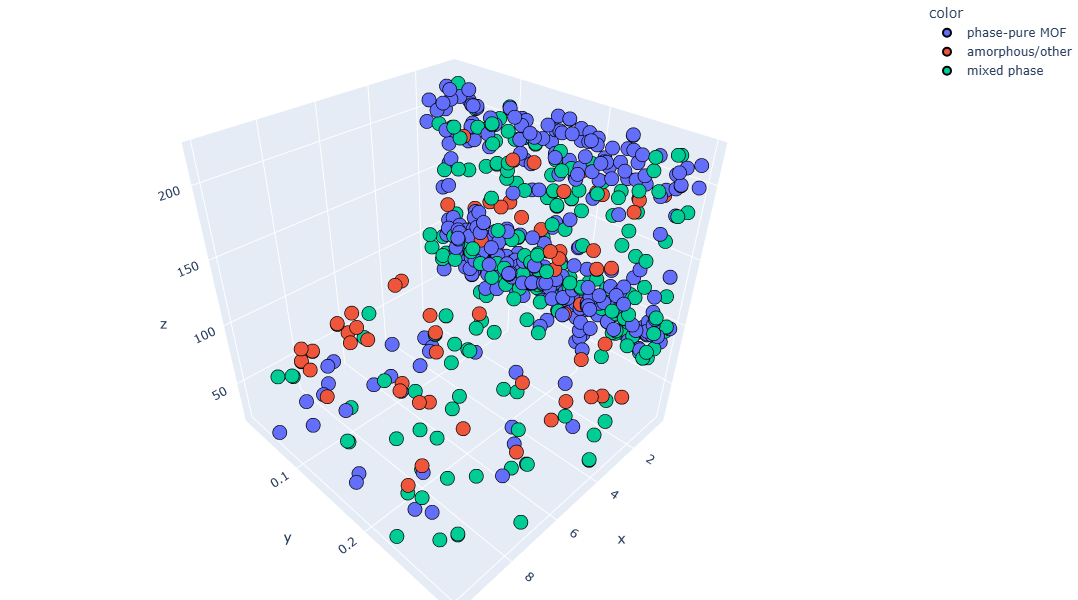

In [17]:
fig = px.scatter_3d(x = Data['feature_1'], y = Data['feature_2'], z = Data['feature_3'], color = Data['target'].astype('str'),
                   width = 700, height = 600)

fig.update_traces(marker = dict(size = 8, line = dict(width = 2, color = 'black')), selector=dict(mode = 'markers'))

fig.update_layout(margin=dict(l=0, r=0, t=0, b=0))

fig.show()

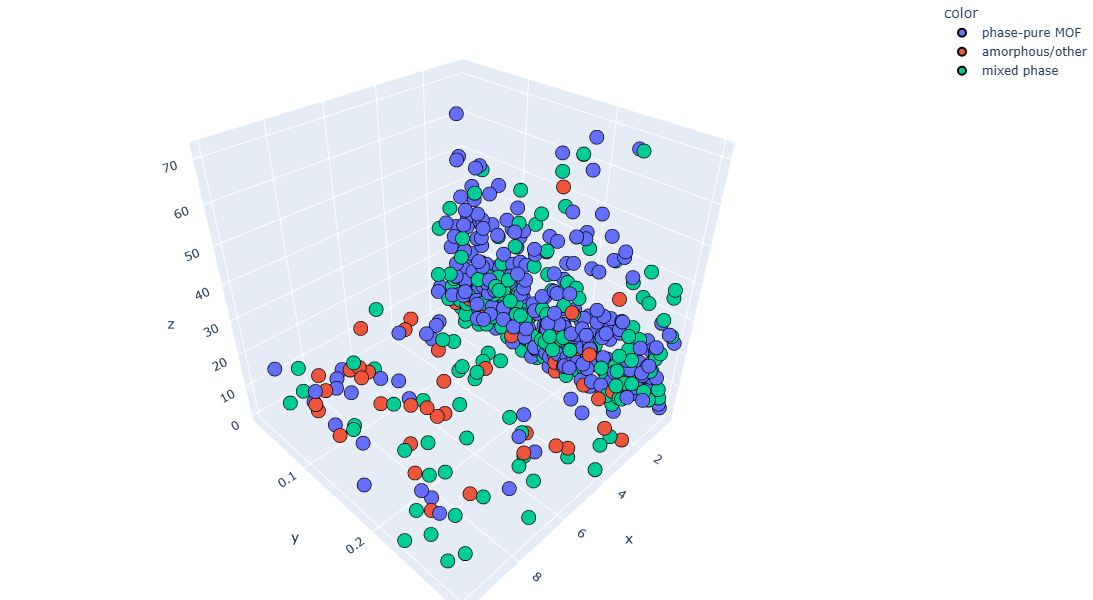

In [18]:
fig = px.scatter_3d(x = Data['feature_1'], y = Data['feature_2'], z = Data['feature_4'], color = Data['target'].astype('str'),
                   width = 700, height = 600)

fig.update_traces(marker = dict(size = 8, line = dict(width = 2, color = 'black')), selector=dict(mode = 'markers'))

fig.update_layout(margin=dict(l=0, r=0, t=0, b=0))

fig.show()

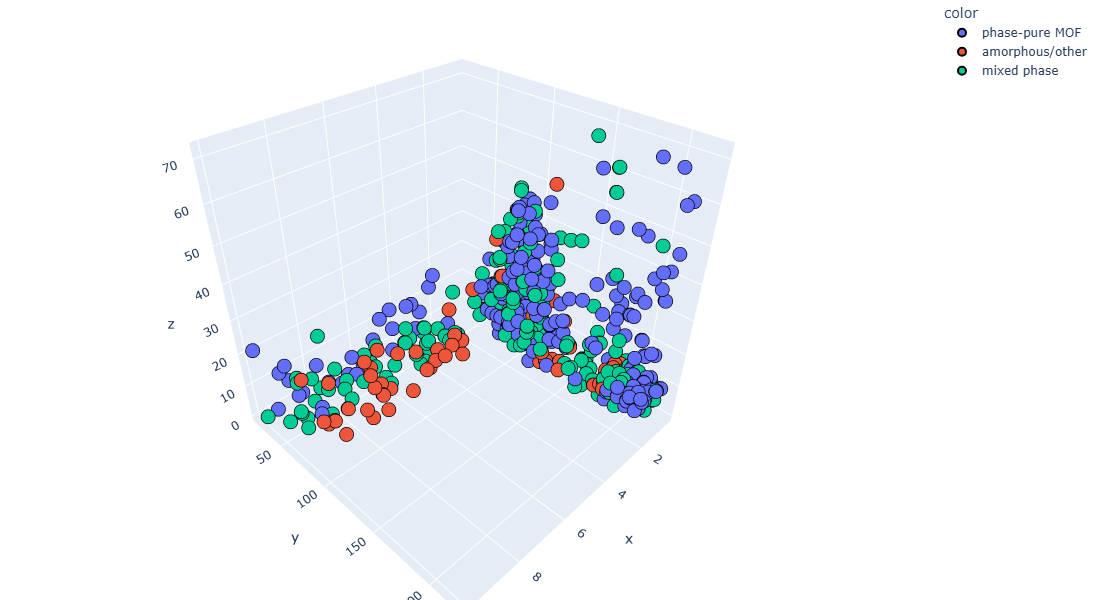

In [19]:
fig = px.scatter_3d(x = Data['feature_1'], y = Data['feature_3'], z = Data['feature_4'], color = Data['target'].astype('str'),
                   width = 700, height = 600)

fig.update_traces(marker = dict(size = 8, line = dict(width = 2, color = 'black')), selector=dict(mode = 'markers'))

fig.update_layout(margin=dict(l=0, r=0, t=0, b=0))

fig.show()

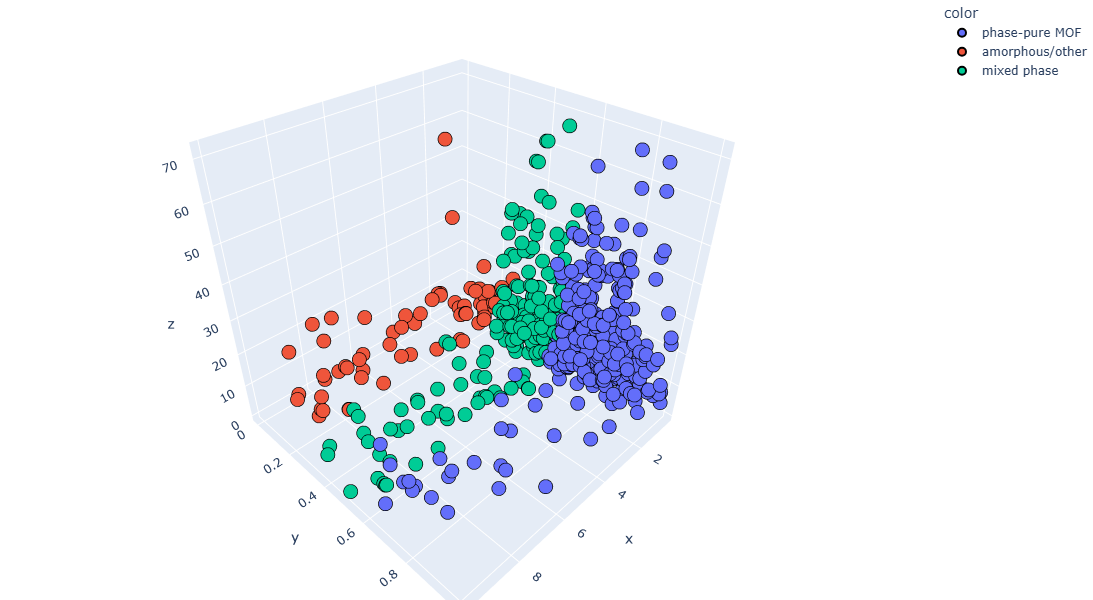

In [20]:
fig = px.scatter_3d(x = Data['feature_1'], y = Data['feature_5'], z = Data['feature_4'], color = Data['target'].astype('str'),
                   width = 700, height = 600)

fig.update_traces(marker = dict(size = 8, line = dict(width = 2, color = 'black')), selector=dict(mode = 'markers'))

fig.update_layout(margin=dict(l=0, r=0, t=0, b=0))

fig.show()

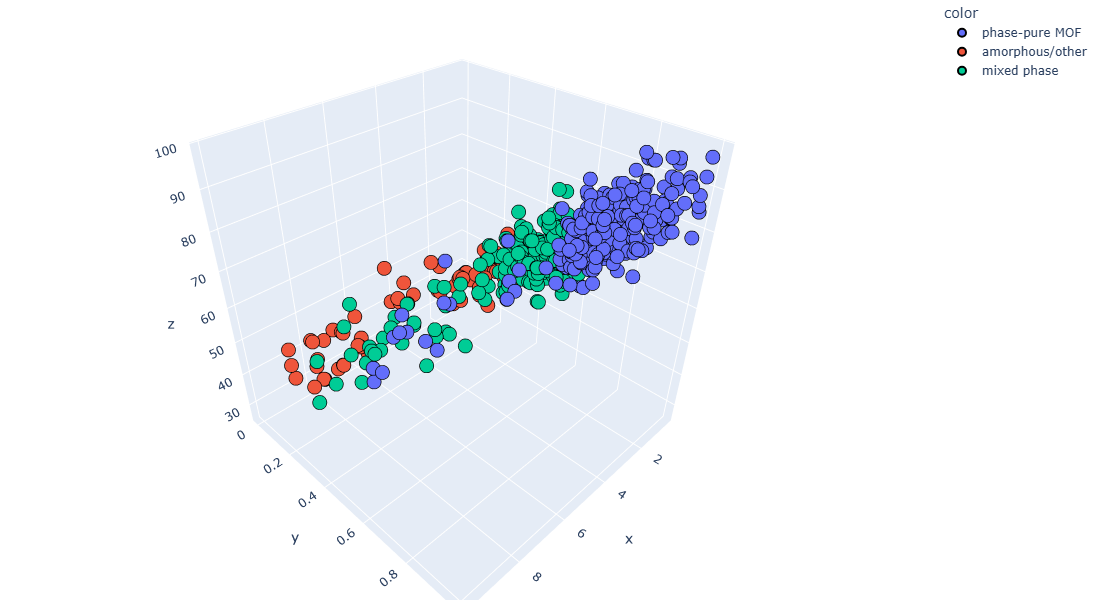

In [21]:
fig = px.scatter_3d(x = Data['feature_1'], y = Data['feature_5'], z = Data['feature_6'], color = Data['target'].astype('str'),
                   width = 700, height = 600)

fig.update_traces(marker = dict(size = 8, line = dict(width = 2, color = 'black')), selector=dict(mode = 'markers'))

fig.update_layout(margin=dict(l=0, r=0, t=0, b=0))

fig.show()

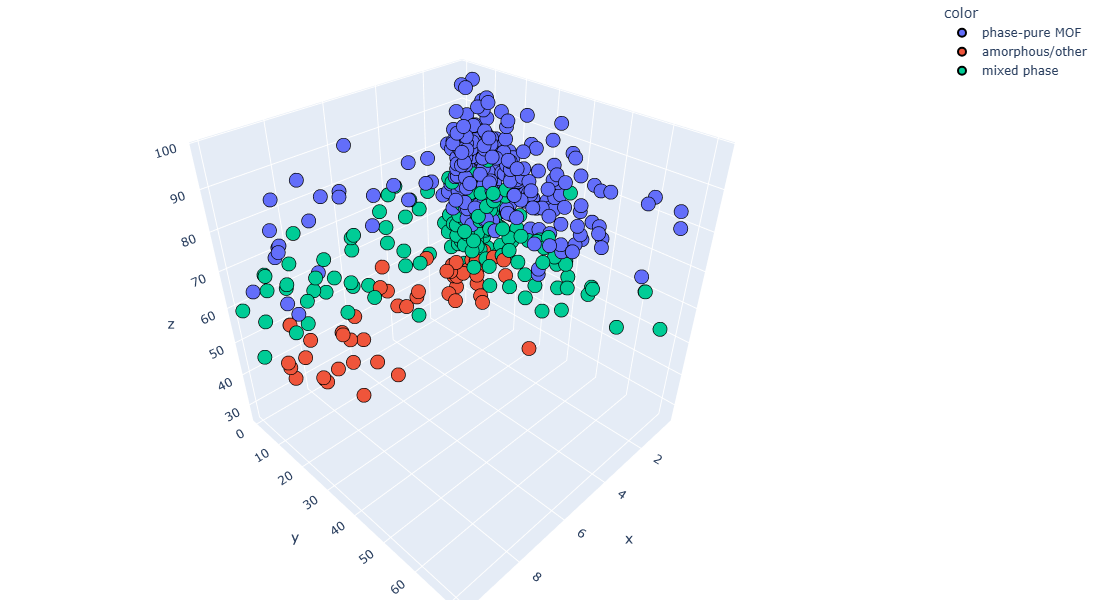

In [23]:
fig = px.scatter_3d(x = Data['feature_1'], y = Data['feature_4'], z = Data['feature_6'], color = Data['target'].astype('str'),
                   width = 700, height = 600)

fig.update_traces(marker = dict(size = 8, line = dict(width = 2, color = 'black')), selector=dict(mode = 'markers'))

fig.update_layout(margin=dict(l=0, r=0, t=0, b=0))

fig.show()

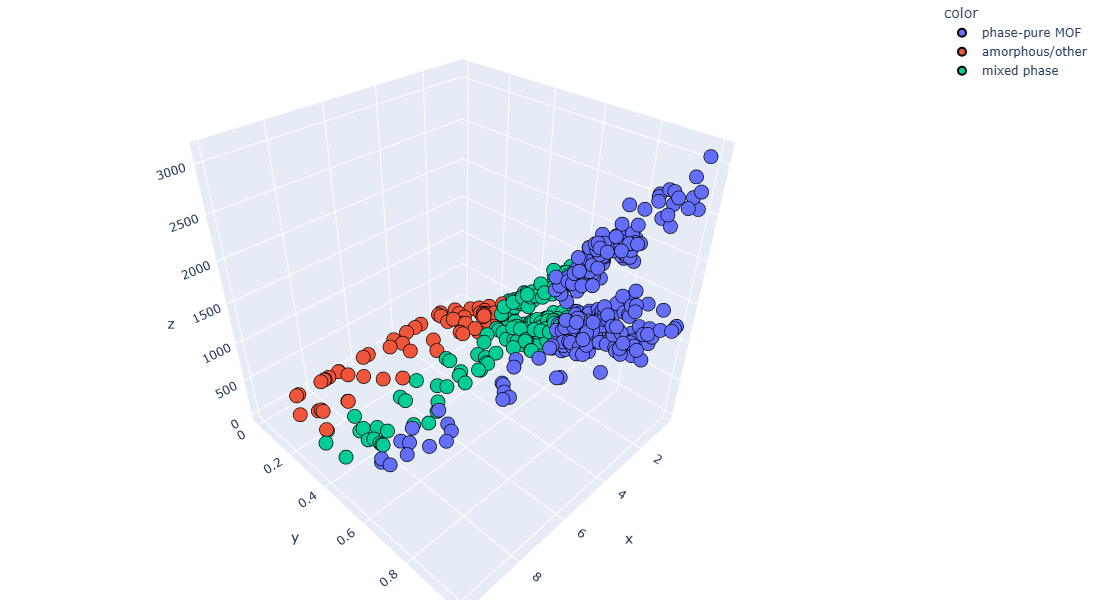

In [25]:
fig = px.scatter_3d(x = Data['feature_1'], y = Data['feature_5'], z = Data['feature_7'], color = Data['target'].astype('str'),
                   width = 700, height = 600)

fig.update_traces(marker = dict(size = 8, line = dict(width = 2, color = 'black')), selector=dict(mode = 'markers'))

fig.update_layout(margin=dict(l=0, r=0, t=0, b=0))

fig.show()

In [26]:
Data.head(2)

,feature_1,feature_2,feature_3,feature_4,feature_5,target,feature_6,feature_7
0,0.84,0.104,210.7,35.30,0.673,phase-pure MOF,80.0,609.0
1,0.92,0.091,108.1,8.49,0.751,phase-pure MOF,68.2,818.0


## for Features 1, 2, 3

In [27]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

In [28]:
cols_1 = Data.columns[0:3]
Data[cols_1] = scaler.fit_transform(Data[cols_1])

In [30]:
covar_matrix_1 = np.cov([Data.iloc[:,0], Data.iloc[:,1], Data.iloc[:,2]])
print(covar_matrix_1)

[[ 1.00151745 -0.0541496  -0.49840565]
 [-0.0541496   1.00151745  0.0744198 ]
 [-0.49840565  0.0744198   1.00151745]]


In [33]:
eigen_values_1, eigen_vectors_1 = np.linalg.eig(covar_matrix_1)
eigen_vectors_1

array([[-0.69456651,  0.70491984, -0.14375459],
       [ 0.17407827, -0.02920686, -0.98429859],
       [ 0.69805023,  0.70868538,  0.10242512]])

In [34]:
eigen_values_1

array([1.51599438, 0.502693  , 0.98586497])

In [35]:
pc_1 = eigen_vectors_1[0:2]
pc_1

array([[-0.69456651,  0.70491984, -0.14375459],
       [ 0.17407827, -0.02920686, -0.98429859]])

In [37]:
transformed_Data_1 = np.dot(Data.iloc[:, 0:3], pc_1.T)


new_Data_1 = pd.DataFrame(transformed_Data_1, columns = ['PC1', 'PC2'])
new_Data_1['target'] = Data['target'].values

new_Data_1.head(2)

,PC1,PC2,target
0,-0.340579,-1.750077,phase-pure MOF
1,-0.207334,0.129071,phase-pure MOF


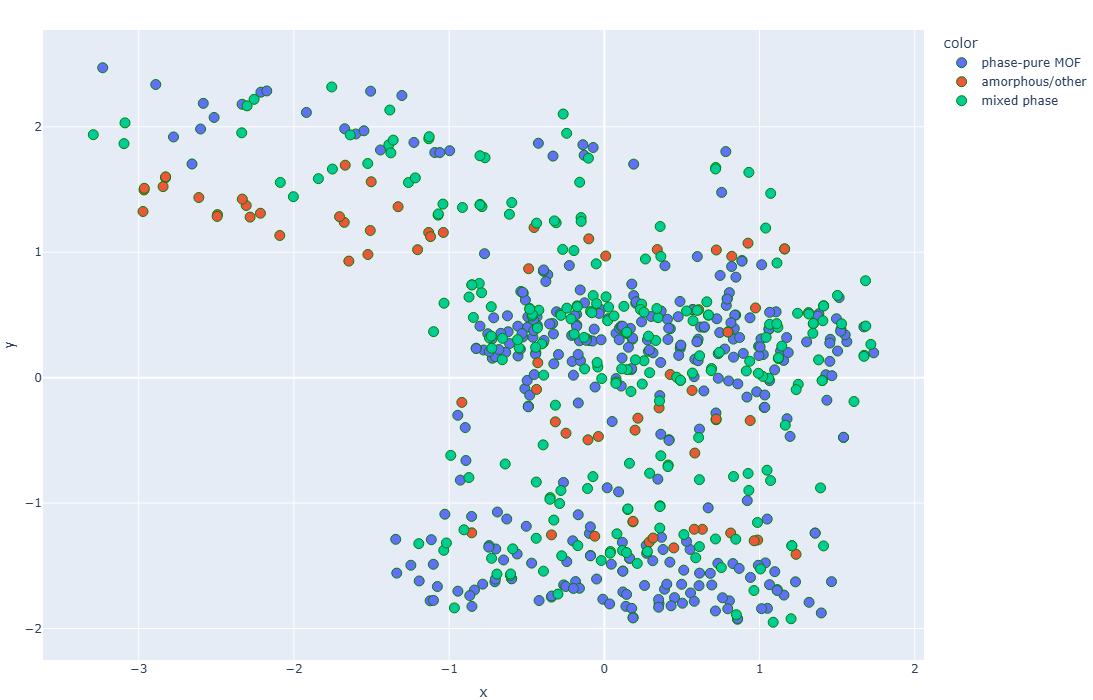

In [38]:
new_Data_1['target'] = new_Data_1['target'].astype('str')

fig = px.scatter(x=new_Data_1['PC1'], y=new_Data_1['PC2'], 
                   color = new_Data_1['target'], width=900, height=700)

fig.update_traces(marker = dict(size = 10, line = dict(width = 1, color='green')),
                 selector = dict(mode='markers'))

fig.update_layout(margin=dict(l=0, r=0, t=30, b=0),            # removes the white space
                  scene_camera=dict(eye=dict(x=1.4, y=1.4, z=1.0)))   # zooms in a little

fig.show()

## for Features 1, 3, 4

In [40]:
Data.head(2)

,feature_1,feature_2,feature_3,feature_4,feature_5,target,feature_6,feature_7
0,-0.574776,-0.703366,1.697213,35.30,0.673,phase-pure MOF,80.0,609.0
1,-0.536604,-0.863714,-0.200402,8.49,0.751,phase-pure MOF,68.2,818.0


In [39]:
scaler_2 = StandardScaler()


In [46]:
cols_2 = ['feature_1',	'feature_3',	'feature_4']
Data[cols_2] = scaler_2.fit_transform(Data[cols_2])

In [47]:
covar_matrix_2 = np.cov([Data.iloc[:,0], Data.iloc[:,2], Data.iloc[:,3]])
print(covar_matrix_2)

[[ 1.00151745 -0.49840565 -0.30623894]
 [-0.49840565  1.00151745  0.15714331]
 [-0.30623894  0.15714331  1.00151745]]


In [48]:
eigen_values_2, eigen_vectors_2 = np.linalg.eig(covar_matrix_2)
eigen_vectors_2

array([[ 0.66028285, -0.73871447,  0.13537905],
       [-0.60275868, -0.62878665, -0.49123245],
       [-0.44800506, -0.24275146,  0.8604436 ]])

In [50]:
pc_2 = eigen_vectors_2[0:2]
pc_2

array([[ 0.66028285, -0.73871447,  0.13537905],
       [-0.60275868, -0.62878665, -0.49123245]])

In [51]:
transformed_Data_2 = np.dot(Data.iloc[:, [0,2,3]], pc_2.T)


new_Data_2 = pd.DataFrame(transformed_Data_2, columns = ['PC1', 'PC2'])
new_Data_2['target'] = Data['target'].values

new_Data_2.head(2)

,PC1,PC2,target
0,-1.426885,-1.469619,phase-pure MOF
1,-0.283134,0.728359,phase-pure MOF


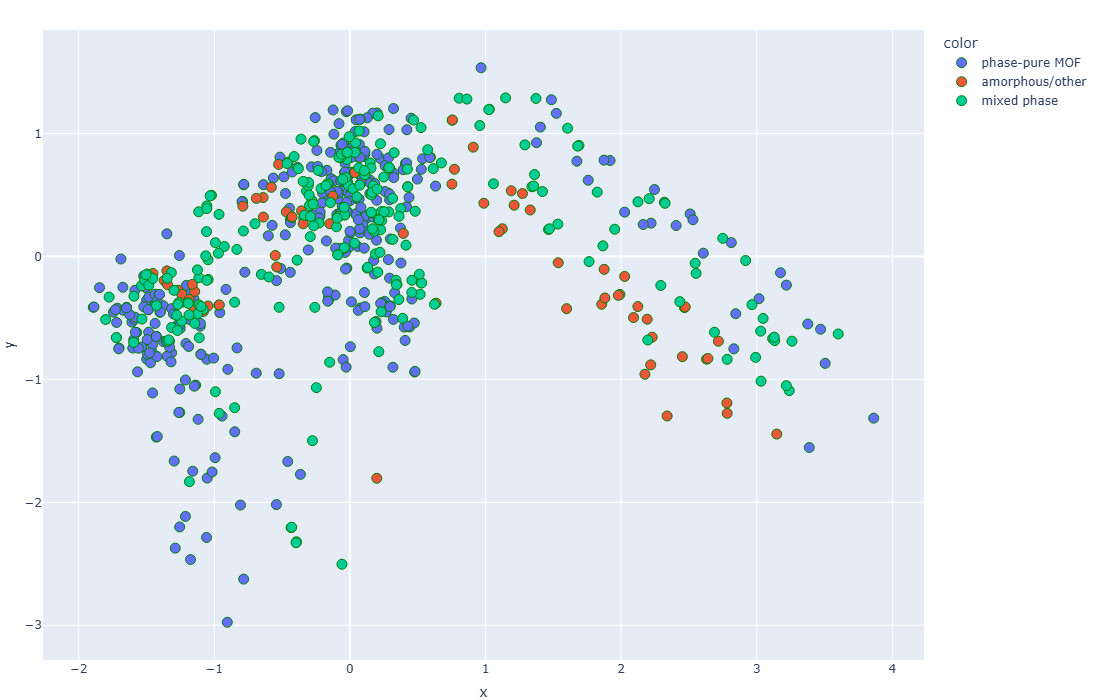

In [53]:
new_Data_2['target'] = new_Data_2['target'].astype('str')


fig = px.scatter(x=new_Data_2['PC1'], y=new_Data_2['PC2'], 
                   color = new_Data_2['target'], width=900, height=700)

fig.update_traces(marker = dict(size = 10, line = dict(width = 1, color='green')),
                 selector = dict(mode='markers'))

fig.update_layout(margin=dict(l=0, r=0, t=30, b=0),            # removes the white space
                  scene_camera=dict(eye=dict(x=1.4, y=1.4, z=1.0)))   # zooms in a little

fig.show()

In [61]:
print(Data[cols_3].isna().sum())

feature_1     0
feature_5     0
feature_6    40
dtype: int64


In [66]:
scaler_3 = StandardScaler()

In [69]:
from sklearn.impute import SimpleImputer

cols_3 = ['feature_1', 'feature_5', 'feature_6']
S_I = SimpleImputer(strategy='median').fit_transform(Data[cols_3])

Data[cols_3] = scaler_3.fit_transform(S_I)

In [70]:
print(Data[cols_3].isna().sum())

feature_1    0
feature_5    0
feature_6    0
dtype: int64


In [71]:
covar_matrix_3 = np.cov([Data.iloc[:, 0], Data.iloc[:, 4], Data.iloc[:, 6]])
print(covar_matrix_3)

[[ 1.00151745 -0.33156464 -0.27391359]
 [-0.33156464  1.00151745  0.87388078]
 [-0.27391359  0.87388078  1.00151745]]


In [74]:
eigen_values_3, eigen_vectors_3  = np.linalg.eig(covar_matrix_3)
eigen_vectors_3

array([[ 0.378195  , -0.92422035, -0.05277577],
       [-0.66023258, -0.2293304 , -0.71519263],
       [-0.6488925 , -0.30532656,  0.696932  ]])

In [75]:
pc_3 = eigen_vectors_3[0:2]
pc_3

array([[ 0.378195  , -0.92422035, -0.05277577],
       [-0.66023258, -0.2293304 , -0.71519263]])

In [76]:
transformed_Data_3 = np.dot(Data.iloc[:, 0:3], pc_3.T)


new_Data_3 = pd.DataFrame(transformed_Data_3, columns = ['PC1', 'PC2'])
new_Data_3['target'] = Data['target'].values

new_Data_3.head(2)

,PC1,PC2,target
0,0.343116,-0.673045,phase-pure MOF
1,0.605898,0.695685,phase-pure MOF


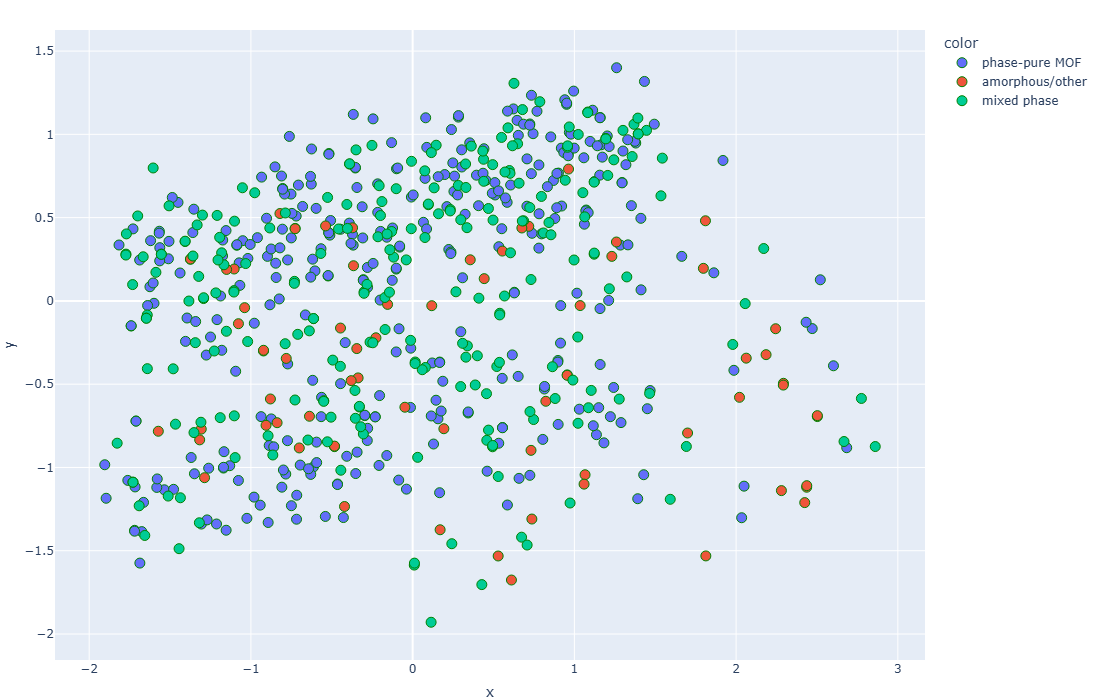

In [77]:
new_Data_3['target'] = new_Data_3['target'].astype('str')

fig = px.scatter(x=new_Data_3['PC1'], y=new_Data_3['PC2'], 
                   color = new_Data_3['target'], width=900, height=700)

fig.update_traces(marker = dict(size = 10, line = dict(width = 1, color='green')),
                 selector = dict(mode='markers'))

fig.update_layout(margin=dict(l=0, r=0, t=30, b=0),            # removes the white space
                  scene_camera=dict(eye=dict(x=1.4, y=1.4, z=1.0)))   # zooms in a little

fig.show()

In [79]:
Data.head(2)

,feature_1,feature_2,feature_3,feature_4,feature_5,target,feature_6,feature_7
0,-0.574776,-0.703366,1.697213,1.524502,0.385221,phase-pure MOF,0.952850,609.0
1,-0.536604,-0.863714,-0.200402,-0.567769,0.739507,phase-pure MOF,0.037392,818.0


In [82]:
X=Data.iloc[:, [0,1,2,3,4,6,7]]
Y = Data.iloc[:, [5]]


In [99]:
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer

X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size = 0.3)

In [100]:
Si = SimpleImputer(strategy='median')

X_train = Si.fit_transform(X_train)
X_test = Si.transform(X_test)



In [102]:

scale = StandardScaler()
X_train_tr = scale.fit_transform(X_train)
X_test_tr = scale.transform(X_test)

In [126]:
from sklearn.decomposition import PCA

pca = PCA(n_components = 7)

X_train_tr2 = pca.fit_transform(X_train_tr)
X_test_tr2 = pca.transform(X_test_tr)

In [127]:
from sklearn.neighbors import KNeighborsClassifier

kn = KNeighborsClassifier()

kn.fit(X_train_tr2, Y_train.values.ravel())

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",5
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None
Name,Type,Value
"classes_ classes_: array of shape (n_classes,)Class labels known to the classifier","ndarray[object](3,)","['amorphous/other','mixed phase','phase-pure MOF']"
"effective_metric_ effective_metric_: str or callbleThe distance metric used. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'


In [128]:
from sklearn.metrics import accuracy_score

Y_pred = kn.predict(X_test_tr2)
print(accuracy_score(Y_test, Y_pred))

0.8939393939393939


In [129]:
for i in range(1, 7):
    pca = PCA(n_components = i)

    X_train_tr2 = pca.fit_transform(X_train_tr)
    X_test_tr2 = pca.transform(X_test_tr)

    kn = KNeighborsClassifier()
    kn.fit(X_train_tr2, Y_train.values.ravel())

    Y_pred = kn.predict(X_test_tr2)
    print(accuracy_score(Y_test, Y_pred))

0.7626262626262627
0.8636363636363636
0.8535353535353535
0.8838383838383839
0.8737373737373737
0.8787878787878788


In [130]:
pca.explained_variance_

array([2.80548782, 1.33740828, 0.9933025 , 0.87932774, 0.46719595,
       0.42065529])

In [131]:
pca.explained_variance_ratio_

array([0.39991648, 0.19064478, 0.14159321, 0.12534635, 0.06659781,
       0.05996354])

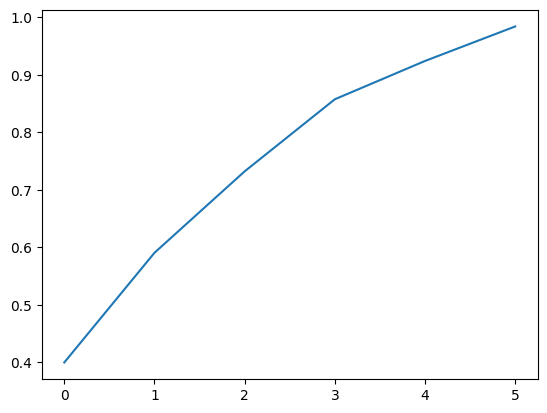

In [134]:
import matplotlib.pyplot as plt

plt.plot(np.cumsum(pca.explained_variance_ratio_))

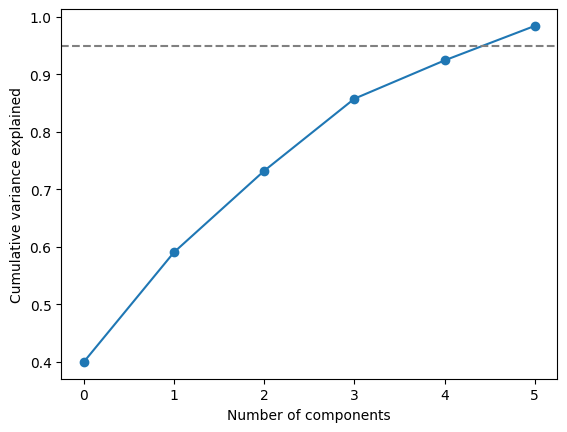

In [137]:
cum = np.cumsum(pca.explained_variance_ratio_)

plt.plot(cum, marker='o')
plt.axhline(0.95, color='gray', linestyle='--')
plt.xlabel('Number of components')
plt.ylabel('Cumulative variance explained')
plt.show()